# BE1 . Data Science
### Qui utilise mon appli ? Identification des utilisateurs de Copilote à partir de leurs traces

**Bureau d'études réalisé par :**

* Hajar Zarguan
* Valentine Ponce
* Guillaume Sumian

**MOD 7.2 Introduction à la science des données** . École Centrale de Lyon . 2026/2027 . Groupe TD 4

### Objectif du projet

Retrouver **quel utilisateur** a réalisé une session dans le logiciel Copilote (Infologic) à partir de la seule trace
de ses actions. C'est un problème de **classification supervisée multi-classe** : 247 utilisateurs (classes),
une prédiction par session de `test.csv`, évaluée avec le **F1 score**.

### Résultat principal

> Le **SVM linéaire** appliqué à une représentation **TF-IDF** des actions, de leurs enchaînements et des composants
> logiciels reconnaît l'utilisateur de **95,7 %** des sessions de validation (F1 micro = 0,957, F1 macro = 0,951),
> et **97,0 % ± 0,3** en validation croisée à 5 plis. La référence naïve n'atteint que 2,3 %.

| Section | Contenu |
| :-----: | ------- |
| **0** | Configuration |
| **1** | Préparation et nettoyage des données |
| **2** | Visualisation et exploration |
| **3** | Modèles de classification |
| **4** | Optimisation du modèle et soumission |
| **5** | Conclusion |

Les fonctions utilisées sont dans le dossier `src/`, un fichier par étape : `configuration.py`, `preparation.py`,
`visualisation.py`, `modeles.py` et `optimisation.py`. Le fichier `analyse_donnees.py` les regroupe, on l'importe sous le nom `AN`.

---
# Section 0 . Configuration

In [1]:
# ===== CONFIGURATION =====
import sys
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.preprocessing import normalize

sys.path.insert(0, "src")        
import analyse_donnees as AN

AN.configurer_graphiques()
BLEU, ORANGE, GRIS = AN.BLEU, AN.ORANGE, AN.GRIS
pd.set_option("display.max_columns", 30)

---
# Section 1 . Préparation et nettoyage des données

## 1.1 Lecture des données

Les lignes n'ont pas toutes le même nombre de champs (de quelques actions à plusieurs milliers)
On utilise deux représentations des mêmes fichiers :
**format large** : une colonne par jeton représenté par `read_ds` pour avoir les statistiques par utilisateur, test du χ² 
**une ligne par session** :  avec des variables construites la fonction  `construire_table_sessions`  pour faire les modèles 



In [2]:
# ===== PRÉPARATION : lecture au format large =====
features_train = AN.read_ds("train")
features_test = AN.read_ds("test")
features_train["util"] = pd.Categorical(features_train["util"])
print("train :", features_train.shape, "| test :", features_test.shape)

AN.describe_data(features_train)
features_train[["util", "navigateur"]].describe()

train : (3279, 14470) | test : (324, 7726)


Nombre de sessions,"3,279"
Nombre d'utilisateurs,247
Sessions par utilisateur (min / médiane / max),4 / 12 / 75
Navigateurs distincts,4
Sessions sans aucune action,0
"Sessions en double (même utilisateur, même trace)",0


,util,navigateur
count,3279,3279
unique,247,4
top,skm,Firefox
freq,75,1466


**Ce que l'on observe.** `train.csv` contient **3 279 sessions** réalisées par **247 utilisateurs**, `test.csv`
**324 sessions** à attribuer. Au format large, le train occupe 14 470 colonnes : c'est la longueur de la session la
plus longue, les autres lignes sont complétées par des cases vides. Chaque utilisateur a entre **4 et 75 sessions**
(médiane 12) ; le plus présent est **skm** (75 sessions) et le navigateur le plus fréquent est Firefox (1 466 sessions).

Pour chaque session, `decrire_session` découpe chaque jeton `Nom(écran)<configuration>$chaîne$1` en ses
différentes parties et calcule quelques indicateurs : nombre d'actions, durée (dernier marqueur `tXX`), cadence,
nombre de types d'action différents, entropie des types d'action, nombre d'écrans. Elle prépare aussi trois
« textes » qui serviront pour la préparation du TF-IDF (Term Frequency–Inverse Document Frequency): la suite des jetons complets, la suite des types d'action et la liste des
composants logiciels (écrans, configurations, chaînes)

In [3]:
# ===== PRÉPARATION : une ligne par session =====
table_train, lignes_vides_train = AN.construire_table_sessions("train.csv", avec_utilisateur=True)
table_test, lignes_vides_test = AN.construire_table_sessions("test.csv", avec_utilisateur=False)

colonnes_affichees = ["util", "navigateur", "n_actions", "duree_s", "cadence", "nb_types", "entropie", "nb_ecrans"]
table_train[colonnes_affichees].head()

,util,navigateur,n_actions,duree_s,cadence,nb_types,entropie,nb_ecrans
0,nuh,Firefox,2514,2905,0.865404,19,3.111266,7
1,muz,Google Chrome,90,230,0.391304,11,2.335543,5
2,zrx,Microsoft Edge,608,750,0.810667,21,3.699711,17
3,pou,Firefox,886,1445,0.613149,19,3.208865,10
4,ald,Google Chrome,173,275,0.629091,14,3.077299,8


**Ce que l'on observe.** Les sessions sont très différentes les unes des autres : la première compte 2 514 actions
sur près de 50 minutes, la deuxième seulement 90 actions en moins de 4 minutes. La cadence (de 0,4 à 0,9 action
par seconde sur ces exemples), le nombre de types d'action et l'entropie varient aussi : ce sont autant d'indices
sur la façon de travailler de chacun.

## 1.2 Contrôle de la qualité des données
On vérifie les points vus en cours : valeurs manquantes, lignes vides, données redondantes (doublons) et
jetons qui ne respectent pas le format décrit sur Kaggle.

In [4]:
# ===== NETTOYAGE : contrôles de qualité =====
print("TRAIN")
AN.controler_qualite(table_train, lignes_vides_train)

TRAIN


Contrôle,Résultat
Lignes vides dans le fichier,0
Sessions sans aucune action,1
Jetons vides (deux virgules consécutives),0
Jetons qui ne suivent pas le format décrit,9
"Sessions en double (même utilisateur, même trace)",0
Traces identiques attribuées à plusieurs utilisateurs,0


,Contrôle,Résultat
0,Lignes vides dans le fichier,0
1,Sessions sans aucune action,1
2,Jetons vides (deux virgules consécutives),0
3,Jetons qui ne suivent pas le format décrit,9
4,"Sessions en double (même utilisateur, même trace)",0
5,Traces identiques attribuées à plusieurs utili...,0


**Ce que montrent les contrôles.** Les données sont propres : aucune ligne vide, aucun jeton vide, aucun doublon
et aucune trace attribuée à deux utilisateurs différents. On relève seulement :
* **1 session sans aucune action** : elle ne contient que des marqueurs de temps. C'est pour cela que
  `describe_data` (qui regarde seulement si la première case est vide) affichait 0 au-dessus ;
* **9 jetons** qui ne suivent pas le format `Nom(écran)<configuration>$chaîne$1`, sur plus de 2,2 millions.
  C'est négligeable : on les garde tels quels.

## 1.3 Nettoyage
* Les **doublons exacts** (même utilisateur, même trace) sont retirés de `train.csv` : une même session présente
  à la fois dans la partie apprentissage et dans la partie validation donnerait un score trop optimiste.
  Ici il n'y en a aucun, mais la règle reste dans le code pour être sûr.
* Les sessions **sans action** ne contiennent aucune information et sont retirées.
* `test.csv` n'est **pas** nettoyé : chaque ligne doit recevoir une prédiction.

In [5]:
# ===== NETTOYAGE : doublons et sessions vides =====
table_train = AN.nettoyer_sessions(table_train)

1 sessions retirées, 3278 sessions conservées.


**Résultat :** une seule session est retirée (la session vide), il reste **3 278 sessions** pour la suite.

## 1.4 Valeurs aberrantes
La durée des sessions va de quelques secondes à plus de trois heures (11 790 s pour la plus longue).
Ces sessions très longues ne sont pas des erreurs de saisie : ce sont de vraies sessions, qu'il faudra aussi
reconnaître dans `test.csv`. On ne les supprime donc pas pour la modélisation ; on passe la durée et le nombre
d'actions au **logarithme**, ce qui réduit leur poids.

Elles sont en revanche retirées (règle de l'IQR, utilisateur par utilisateur) pour calculer la cadence moyenne de
chaque utilisateur en section 2.5, qui serait sinon dominée par quelques sessions extrêmes.

Sessions considérées comme aberrantes pour la durée : 179


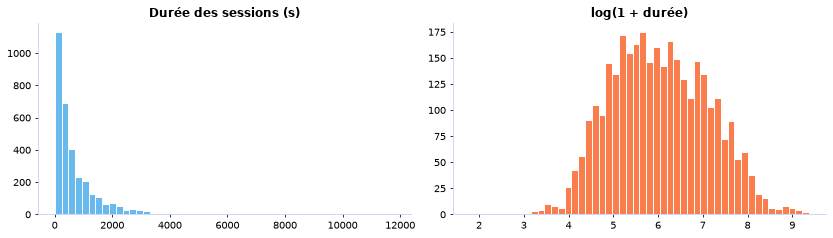

In [6]:
# ===== NETTOYAGE : durée de chaque session et profil par utilisateur =====
profils = features_train.groupby("util", observed=True)["navigateur"].first().reset_index()
profils = AN.temps_par_session(features_train, profils)

features_clean = AN.retirer_sessions_aberrantes(features_train, "max_t")
print(f"Sessions considérées comme aberrantes pour la durée : {len(features_train) - len(features_clean)}")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(table_train["duree_s"], bins=50, color=BLEU, edgecolor="white")
axes[0].set_title("Durée des sessions (s)")
axes[1].hist(table_train["log_duree"], bins=50, color=ORANGE, edgecolor="white")
axes[1].set_title("log(1 + durée)")
plt.tight_layout()
plt.show()

**Ce que l'on observe.** La durée brute est très asymétrique : la plupart des sessions durent moins de
10 minutes, mais quelques-unes dépassent 3 heures. Après le passage au logarithme, la distribution devient presque
**symétrique, en cloche**, centrée vers 5,8 (soit environ 5 minutes) : c'est cette forme qu'on donne aux modèles.
La règle de l'IQR repère **179 sessions** (5,5 %) atypiques pour leur utilisateur ; elles ne sont écartées que pour
le calcul de la cadence en section 2.5.

---
# Section 2 . Visualisation et exploration des données

## 2.1 Utilisateurs et sessions

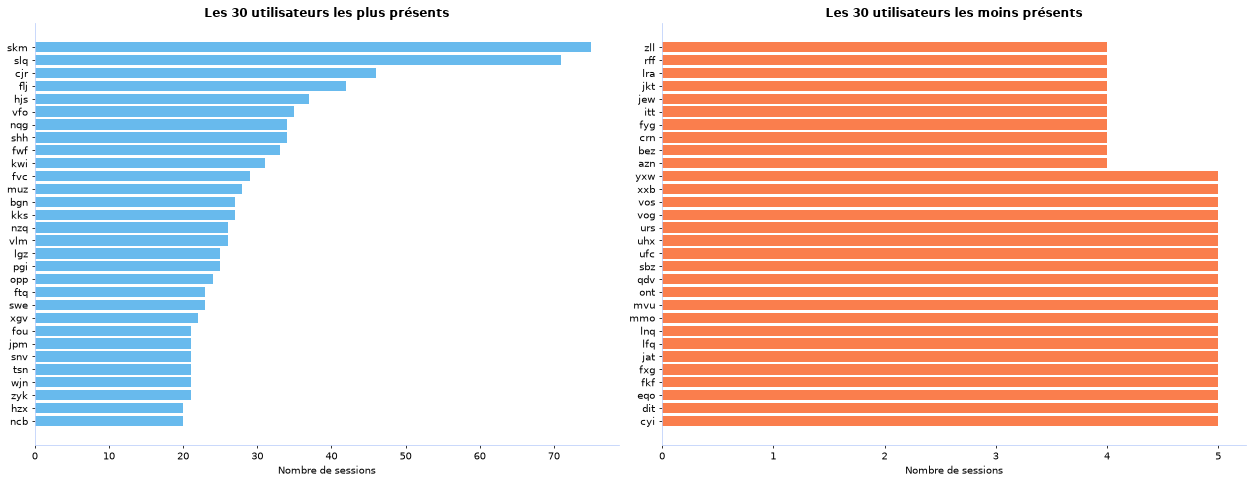

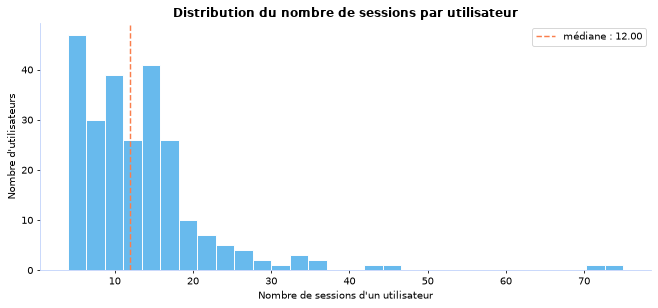

Un utilisateur a en médiane 12 sessions ; le plus présent en a 75.


In [7]:
# ===== VISUALISATION : sessions par utilisateur =====
effectifs = features_train["util"].value_counts()
top30 = effectifs.head(30)
bas30 = effectifs.tail(30)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 7))
axes[0].barh(top30.index.astype(str)[::-1], top30.values[::-1], color=BLEU)
axes[0].set_title("Les 30 utilisateurs les plus présents")
axes[0].set_xlabel("Nombre de sessions")
axes[1].barh(bas30.index.astype(str), bas30.values, color=ORANGE)
axes[1].set_title("Les 30 utilisateurs les moins présents")
axes[1].set_xlabel("Nombre de sessions")
plt.tight_layout()
plt.show()

AN.plot_distribution(effectifs, title="Distribution du nombre de sessions par utilisateur",
                     xlabel="Nombre de sessions d'un utilisateur", ylabel="Nombre d'utilisateurs")
print(f"Un utilisateur a en médiane {effectifs.median():.0f} sessions ; le plus présent en a {effectifs.max()}.")

**Ce que l'on observe.** Deux utilisateurs dominent nettement (**skm** avec 75 sessions et **slq** avec environ 70),
puis le nombre de sessions décroît vite : la moitié des utilisateurs a **12 sessions ou moins**, et une dizaine
n'en a que **4**, le minimum. La distribution a une longue queue vers la droite.

Les utilisateurs les plus présents fournissent beaucoup d'exemples au modèle : ce sont les plus faciles à apprendre.
À l'opposé, ceux qui n'ont que 4 ou 5 sessions n'en auront que 3 ou 4 en apprentissage : c'est sur eux que l'on
attend le plus d'erreurs. Les classes sont donc **déséquilibrées** : on utilisera un découpage **stratifié** et on
suivra aussi le F1 **macro**, qui donne le même poids à chaque utilisateur.

## 2.2 Navigateurs utilisés
Est-ce que les utilisateurs sont fidèles à leur navigateur ? Quel navigateur est le plus utilisé ?

Nombre maximum de navigateurs utilisés par un utilisateur : 1


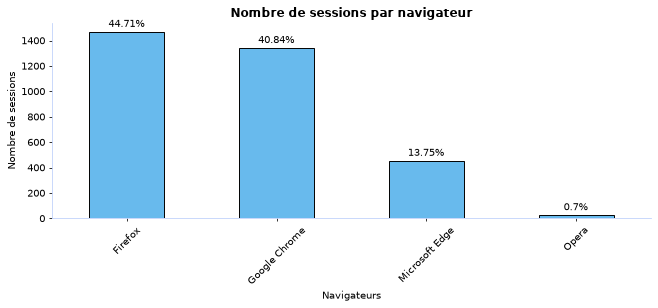

,sessions,part (%),utilisateurs l'ayant utilisé
navigateur,,,
Firefox,1466,44.71,114
Google Chrome,1339,40.84,93
Microsoft Edge,451,13.75,39
Opera,23,0.70,1


In [8]:
# ===== VISUALISATION : navigateurs =====
AN.browsers_analysis(features_train)

**Ce que l'on observe.** Aucun utilisateur ne change de navigateur (au plus 1 navigateur par personne).
Firefox (44,7 % des sessions, 114 utilisateurs) et Chrome (40,8 %, 93 utilisateurs) dominent, devant Edge
(13,8 %, 39 utilisateurs). **Opera n'est utilisé que par un seul utilisateur** : toute session sous Opera lui
appartient forcément.

Le navigateur ne suffit pas à identifier quelqu'un, mais il divise le nombre de candidats par 2 à 6 selon le cas.
Il sera codé en **one-hot** dans les modèles.

## 2.3 Analyse des actions
### Types d'action et test du X2
Le type d'une action est son nom, sans l'écran ni la configuration (par exemple « Exécution d'un bouton »).

Pour chaque type d'action, le test du χ² compare ses fréquences d'utilisation chez les différents utilisateurs avec ce que l'on observerait si tout le monde l'employait dans les mêmes proportions. 

Plus le score est élevé, plus l'usage de ce type d'action dépend de l'utilisateur, donc plus il est utile pour reconnaître quelqu'un.


On retient les types dont le score dépasse 25 % du score maximal, puis on regarde leurs corrélations.

Nombre total d'actions : 2,270,247


,Occurrences,Part des actions (%),Sessions où il apparaît,Utilisateurs qui l'emploient
Type d'action,,,,
Exécution d'un bouton,510645,22.49,3275,247
Saisie dans un champ,265633,11.70,3206,247
Sélection d'un écran,206813,9.11,3026,246
Fermeture d'une dialogue,171026,7.53,3223,247
Affichage d'une dialogue,168928,7.44,3219,247
Lancement d'une action générique,115283,5.08,2906,246
Sélection d’un onglet,109209,4.81,2714,245
Raccourci,82176,3.62,1944,226
Création d'un écran,76930,3.39,3134,246


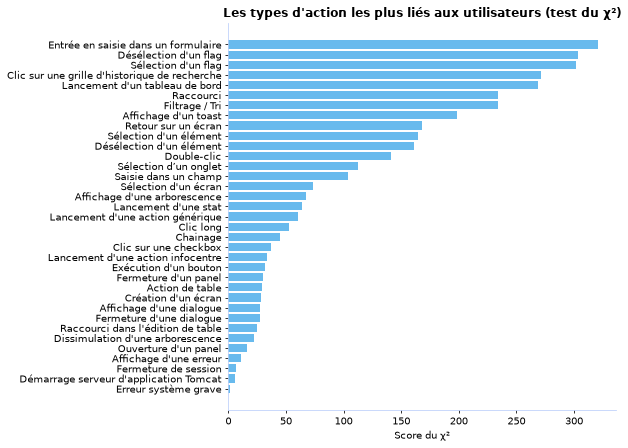

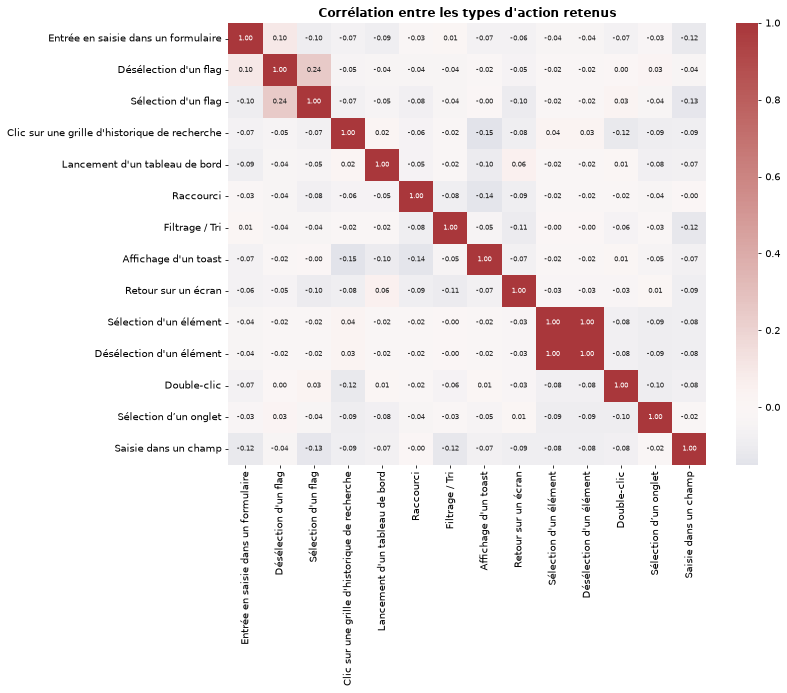

14 types d'action retenus : ['Entrée en saisie dans un formulaire', "Désélection d'un flag", "Sélection d'un flag", "Clic sur une grille d'historique de recherche", "Lancement d'un tableau de bord", 'Raccourci', 'Filtrage / Tri', "Affichage d'un toast", 'Retour sur un écran', "Sélection d'un élément", "Désélection d'un élément", 'Double-clic', 'Sélection d’un onglet', 'Saisie dans un champ']


In [ ]:
# ===== VISUALISATION : types d'action, χ² et corrélations =====
actions_selectionnees = AN.actions_analysis(features_train)
print(f"{len(actions_selectionnees)} types d'action retenus :", actions_selectionnees)

**Ce que l'on observe.**
* Le train contient **2 270 247 actions**. Les plus fréquentes sont « Exécution d'un bouton » (22,5 %),
  « Saisie dans un champ » (11,7 %) et « Sélection d'un écran » (9,1 %). Elles sont utilisées par les 247
  utilisateurs : elles décrivent l'usage du logiciel, pas la personne.
* Le test du χ² le confirme : ces actions très courantes ont des scores **faibles** (environ 30 pour
  « Exécution d'un bouton »), alors que les actions plus rares sont les plus discriminantes :
  **« Entrée en saisie dans un formulaire »** (≈ 320), **« Sélection / Désélection d'un flag »** (≈ 300),
  « Clic sur une grille d'historique de recherche », « Lancement d'un tableau de bord », « Raccourci »,
  « Filtrage / Tri ». **14 types d'action** dépassent le seuil de 25 % du meilleur score.
* Dans la matrice de corrélation, « Sélection d'un élément » et « Désélection d'un élément » sont corrélées à
  **1,00** : l'une ne va jamais sans l'autre, elles portent la même information. Les autres corrélations restent
  très faibles (|r| < 0,25) : les actions retenues apportent des informations **complémentaires**.

Les modèles linéaires régularisés et les forêts aléatoires supportent bien ces redondances : on garde donc toutes
les actions dans les variables du modèle, le χ² sert ici à **comprendre** quelles actions distinguent les utilisateurs.

### Types d'action sur- et sous-représentés selon les utilisateurs
Pour chacun des 30 utilisateurs les plus actifs, on compare la part de chaque type d'action dans ses actions à la
part moyenne, en log base 2 : **+1** = deux fois plus que la moyenne (orange), **−1** = deux fois moins (bleu),
**0** = comme tout le monde (blanc). Chaque ligne est une sorte d'« empreinte » de l'utilisateur.

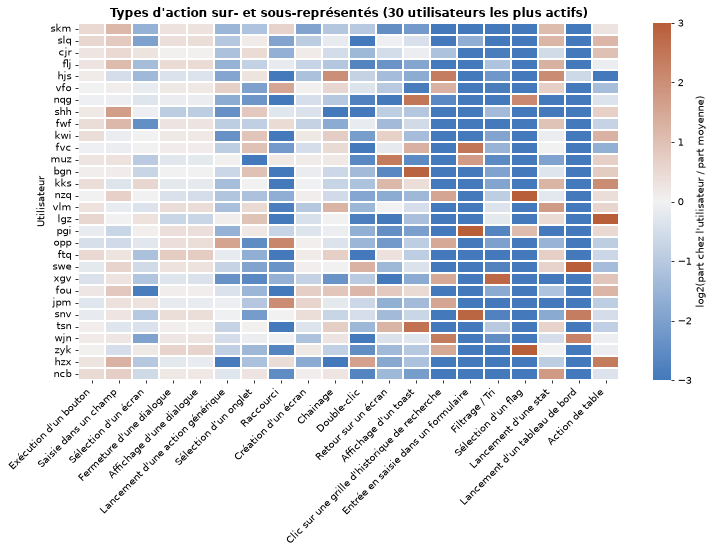

In [10]:
# ===== VISUALISATION : empreinte des utilisateurs =====
compteur_types = CountVectorizer(token_pattern=r"\S+", lowercase=False)
X_types = compteur_types.fit_transform(table_train["doc_types"])
noms_types = [nom.replace("_", " ") for nom in compteur_types.get_feature_names_out()]

parts = pd.DataFrame(X_types.toarray(), columns=noms_types)
parts["util"] = table_train["util"].to_numpy()
comptes_util = parts.groupby("util").sum()
part_util = comptes_util.div(table_train.groupby("util")["n_actions"].sum(), axis=0)
part_moyenne = comptes_util.sum() / table_train["n_actions"].sum()
types_frequents = part_moyenne.sort_values(ascending=False).head(20).index
ecart = np.log2((part_util + 1e-4) / (part_moyenne + 1e-4)).loc[top30.index.astype(str), types_frequents]

plt.figure(figsize=(11, 8))
sns.heatmap(ecart, cmap=sns.diverging_palette(250, 25, as_cmap=True), center=0, vmin=-3, vmax=3,
            linewidths=0.4, linecolor="white", cbar_kws={"label": "log2(part chez l'utilisateur / part moyenne)"})
plt.title("Types d'action sur- et sous-représentés (30 utilisateurs les plus actifs)")
plt.xlabel("")
plt.ylabel("Utilisateur")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Ce que l'on observe.** Les colonnes de gauche (actions très courantes : bouton, saisie, dialogues) sont
presque blanches pour tout le monde : chacun les utilise dans les mêmes proportions. Les colonnes de droite
(grille d'historique, entrée en saisie dans un formulaire, filtrage, flags, statistiques, tableau de bord, action
de table) sont au contraire très contrastées : bleu foncé pour la plupart des utilisateurs, qui ne les emploient
presque jamais, et rouge pour quelques-uns, qui les emploient beaucoup.

C'est exactement l'idée du **TF-IDF** utilisé en section 3 : donner plus de poids aux actions rares, qui
caractérisent une personne, qu'aux actions que tout le monde fait.

### Enchaînement des actions
On compte les paires d'actions consécutives (« bigrammes »), par exemple « Saisie dans un champ → Exécution d'un
bouton ». Deux personnes peuvent faire les mêmes actions dans un ordre différent : l'ordre est une information
supplémentaire pour les reconnaître.

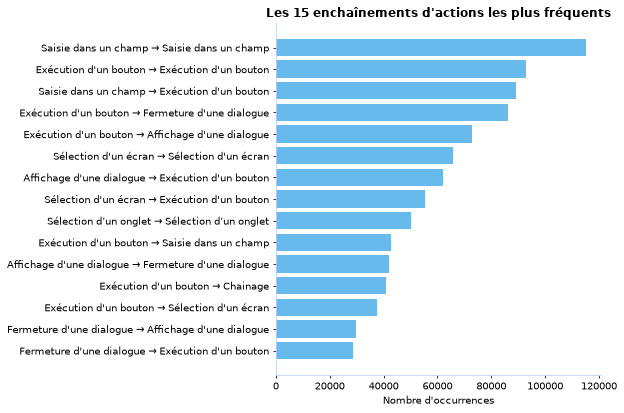

In [11]:
# ===== VISUALISATION : enchaînements d'actions =====
paires = Counter()
for doc in table_train["doc_types"]:
    types_session = doc.split()
    paires.update(zip(types_session, types_session[1:]))

top_paires = paires.most_common(15)[::-1]
plt.figure(figsize=(9, 6))
plt.barh([f"{a.replace('_', ' ')} → {b.replace('_', ' ')}" for (a, b), _ in top_paires],
         [c for _, c in top_paires], color=BLEU)
plt.title("Les 15 enchaînements d'actions les plus fréquents")
plt.xlabel("Nombre d'occurrences")
plt.tight_layout()
plt.show()

**Ce que l'on observe.** Les enchaînements les plus fréquents sont des **répétitions** (« Saisie → Saisie »,
environ 115 000 fois ; « Bouton → Bouton », environ 93 000) et des gestes de travail classiques : **saisir puis
valider** (« Saisie → Bouton », environ 89 000), cliquer puis ouvrir ou fermer une boîte de dialogue.

### Matrice de transition entre les 15 types d'action les plus fréquents
Chaque case donne la probabilité que l'action de la colonne suive l'action de la ligne (chaque ligne fait 100 %).


Si les utilisateurs ont des habitudes d'enchaînement différentes, les suites d'actions aideront le modèle : on les utilisera comme variables en Section 3.

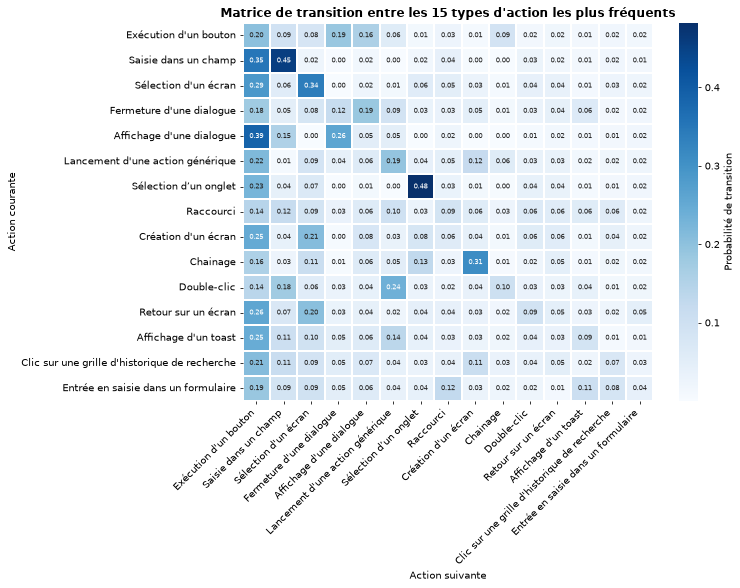

In [12]:
# ===== VISUALISATION : matrice de transition =====
tous_types = Counter(a for doc in table_train["doc_types"] for a in doc.split())
frequents = [ty for ty, _ in tous_types.most_common(15)]
transitions = pd.DataFrame(0.0, index=frequents, columns=frequents)
for (a, b), c in paires.items():
    if a in transitions.index and b in transitions.columns:
        transitions.loc[a, b] = c
transitions = transitions.div(transitions.sum(axis=1), axis=0)
etiquettes = [ty.replace("_", " ") for ty in frequents]

plt.figure(figsize=(11, 8.5))
sns.heatmap(transitions.set_axis(etiquettes).set_axis(etiquettes, axis=1), cmap="Blues", annot=True, fmt=".2f",
            annot_kws={"size": 7}, linewidths=0.4, linecolor="white", cbar_kws={"label": "Probabilité de transition"})
plt.title("Matrice de transition entre les 15 types d'action les plus fréquents")
plt.xlabel("Action suivante")
plt.ylabel("Action courante")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Ce que l'on observe.**
* Les répétitions sont fréquentes : après une « Sélection d'un onglet », l'action suivante est encore une sélection
  d'onglet dans **48 %** des cas ; après une « Saisie dans un champ », une autre saisie dans **45 %** des cas.
* Certains enchaînements sont presque des réflexes : un « Affichage d'une dialogue » est suivi d'un clic sur un
  bouton dans **39 %** des cas, et un « Chainage » (passage d'une fiche à une fiche liée) est suivi de la
  « Création d'un écran » dans **31 %** des cas.
* « Exécution d'un bouton » est l'action suivante la plus probable presque partout (première colonne).

Ces probabilités sont calculées sur tous les utilisateurs ; d'une personne à l'autre, les habitudes diffèrent.
C'est ce que capteront les **bigrammes de types d'action** (groupe `enchainements`) dans les modèles.

## 2.4 Composants logiciels
Les parties entre parenthèses, chevrons et dollars indiquent **où** l'utilisateur travaille dans le logiciel.
Chaque personne n'utilise qu'une partie du logiciel, selon son métier : ces composants sont de bons indices d'identité.

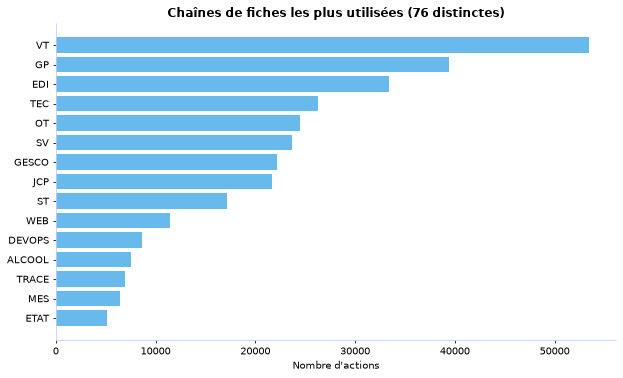

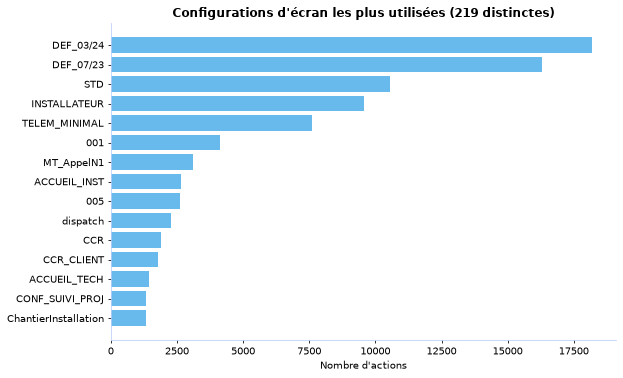

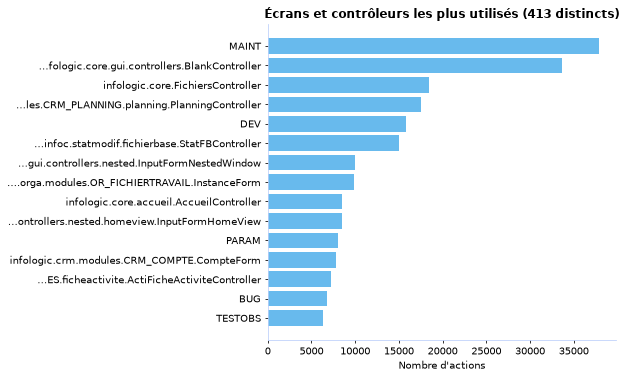

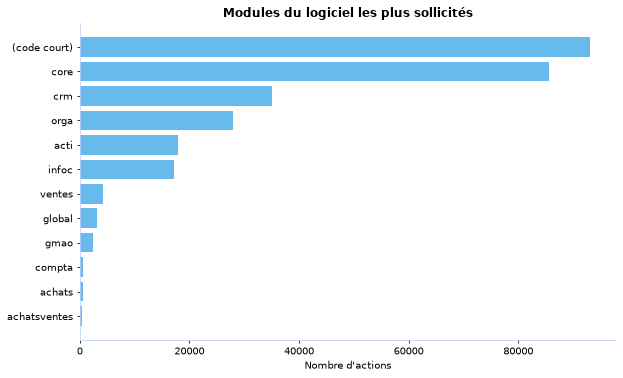

In [13]:
# ===== VISUALISATION : chaînes, configurations, écrans et modules =====
chaines = Counter(c for liste in table_train["chaines"] for c in liste)
AN.barres_top(chaines, f"Chaînes de fiches les plus utilisées ({len(chaines)} distinctes)", "Nombre d'actions")

configs = Counter(c for liste in table_train["configs"] for c in liste)
AN.barres_top(configs, f"Configurations d'écran les plus utilisées ({len(configs)} distinctes)", "Nombre d'actions")

ecrans = Counter(e for liste in table_train["ecrans"] for e in liste)
AN.barres_top(ecrans, f"Écrans et contrôleurs les plus utilisés ({len(ecrans)} distincts)", "Nombre d'actions")

modules = Counter()
for e, c in ecrans.items():
    modules[AN.module(e)] += c
AN.barres_top(modules, "Modules du logiciel les plus sollicités", "Nombre d'actions", n=12)

**Ce que l'on observe.**
* **76 chaînes de fiches** différentes (entre dollars) : les plus utilisées sont `VT`, `GP` et `EDI`. Une chaîne
  indique le circuit de documents sur lequel l'utilisateur travaille, donc son métier.
* **219 configurations d'écran** (entre chevrons) : les configurations par défaut `DEF_03/24` et `DEF_07/23`
  dominent, devant `STD` et `INSTALLATEUR`. Beaucoup d'autres sont rares, parfois propres à une équipe.
* Pour les **écrans**, les plus ouverts sont `MAINT`, la page vide `BlankController` et l'écran de fichiers ;
  par **module**, les écrans à code court et le cœur du logiciel (`core`) arrivent en tête, devant `crm`, `orga`,
  `acti` et `infoc`. La comptabilité et les achats sont très peu présents : les testeurs travaillent surtout
  sur la relation client, l'organisation et les activités.

Le même test du χ² que pour les actions permet de repérer les composants les plus liés à un utilisateur :

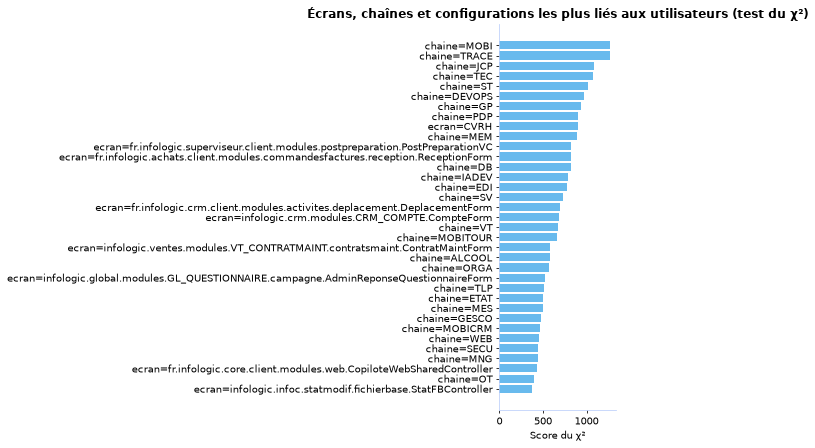

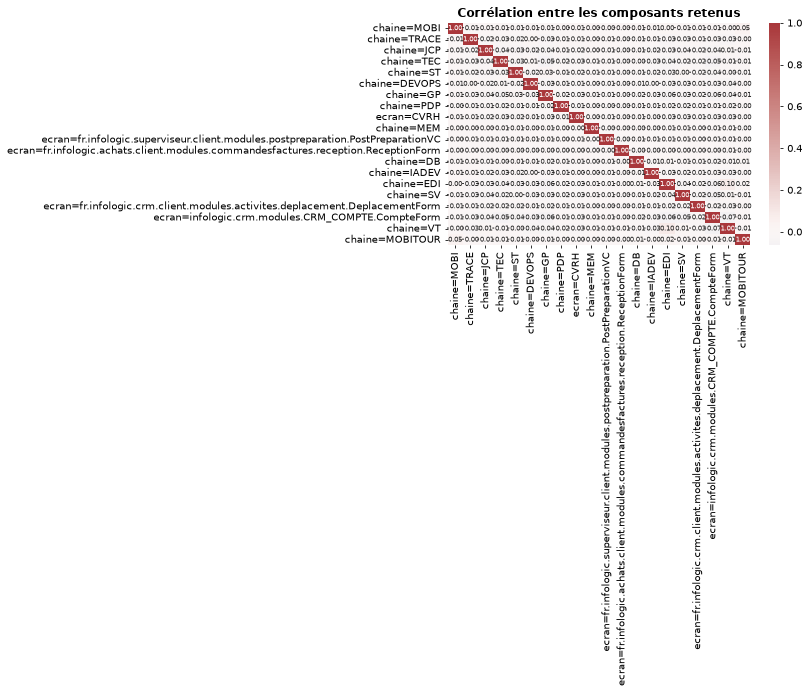

39 composants retenus


In [14]:
# ===== VISUALISATION : χ² des composants logiciels =====
composants_selectionnes = AN.analyser_composants_logiciels(features_train)
print(f"{len(composants_selectionnes)} composants retenus")

**Ce que l'on observe.** **39 composants** dépassent le seuil. Les chaînes dominent le classement (`MOBI`, `TRACE`,
`JCP`, `TEC`, `ST`, `DEVOPS`…), avec quelques écrans très spécialisés (préparation de commandes, réception
d'achats, frais de déplacement). Leurs scores du χ² montent jusqu'à **environ 1 300**, contre 320 au maximum pour
les types d'action : savoir **où** quelqu'un travaille le distingue bien plus que savoir **quelles** actions il fait.
Les corrélations entre ces composants sont proches de 0 : chacun est propre à un petit groupe d'utilisateurs différent.

## 2.5 Temps et rythme de travail
Un marqueur `tXX` apparaît environ toutes les 5 secondes ; la durée d'une session est la valeur du dernier marqueur.

Plus longue session : 11790 s


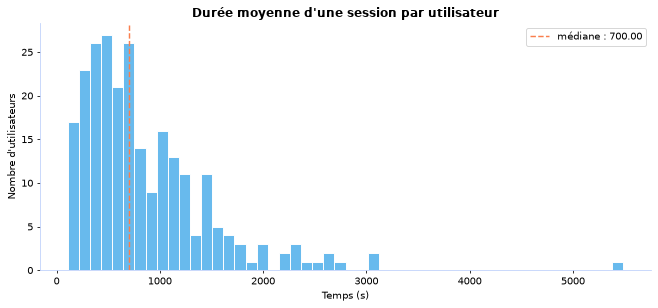

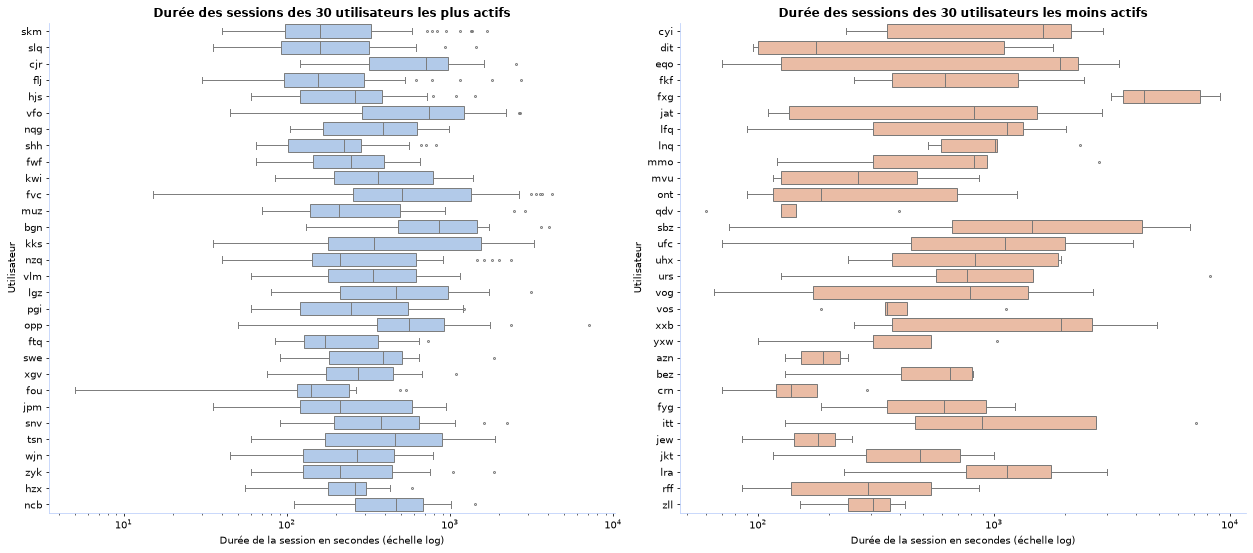

In [15]:
# ===== VISUALISATION : durée des sessions =====
print(f"Plus longue session : {profils['max_t'].max():.0f} s")
AN.plot_distribution(profils["moyenne_t"], title="Durée moyenne d'une session par utilisateur",
                     xlabel="Temps (s)", ylabel="Nombre d'utilisateurs", bins=50)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(18, 8))
for ax, groupe, couleur, titre in [(axes[0], top30, "#a9c9f2", "les plus actifs"),
                                  (axes[1], bas30, "#f5b899", "les moins actifs")]:
    donnees = features_train[features_train["util"].isin(groupe.index)].copy()
    donnees["util"] = donnees["util"].astype(str)
    sns.boxplot(data=donnees, y="util", x=donnees["max_t"].clip(lower=1), order=groupe.index.astype(str),
                color=couleur, fliersize=2, linewidth=1, ax=ax)
    ax.set_xscale("log")
    ax.set_title(f"Durée des sessions des 30 utilisateurs {titre}")
    ax.set_xlabel("Durée de la session en secondes (échelle log)")
    ax.set_ylabel("Utilisateur")
plt.tight_layout()
plt.show()

**Ce que l'on observe.** La durée moyenne d'une session varie beaucoup d'un utilisateur à l'autre : médiane
**700 s** (environ 12 minutes), mais de 2 minutes à plus de 90 minutes. Les boîtes à moustaches confirment
que certains font des sessions systématiquement longues (par exemple **fxg**, autour d'une heure) et d'autres des
sessions très courtes (**qdv**, **vos**, **azn**, **crn**, quelques minutes). La durée apporte donc une information,
mais les boîtes de la plupart des utilisateurs se chevauchent largement : elle ne suffit pas seule.

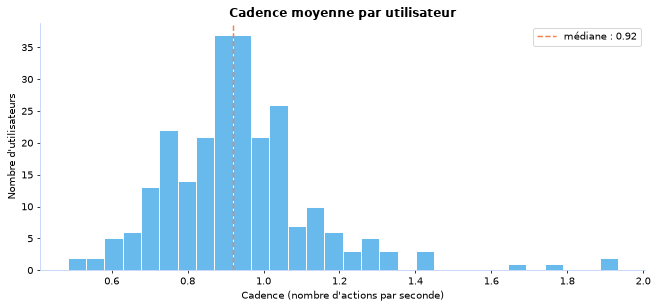

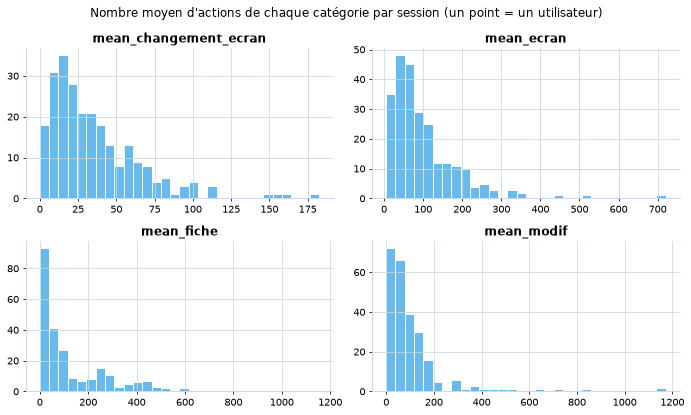

In [16]:
# ===== VISUALISATION : cadence et catégories d'actions =====
profils = AN.rapidite_util(features_clean, profils)
AN.plot_distribution(profils["rapidite"], title="Cadence moyenne par utilisateur",
                     xlabel="Cadence (nombre d'actions par seconde)", ylabel="Nombre d'utilisateurs")

profils = AN.stat_actions(features_train, profils)
profils[["mean_changement_ecran", "mean_ecran", "mean_fiche", "mean_modif"]].hist(bins=30, color=BLEU,
                                                                                  edgecolor="white", figsize=(10, 6))
plt.suptitle("Nombre moyen d'actions de chaque catégorie par session (un point = un utilisateur)")
plt.tight_layout()
plt.show()

**Ce que l'on observe.** La cadence moyenne est de **0,92 action par seconde** (médiane), et la plupart des
utilisateurs se situent entre 0,6 et 1,3. Quelques-uns dépassent 1,6 : ce sont sans doute des utilisateurs
qui maîtrisent très bien le logiciel ou utilisent beaucoup les raccourcis. Les nombres moyens d'actions par
catégorie (avec écran, avec changement de configuration…) sont eux aussi très étalés d'un utilisateur à l'autre.
Le rythme est un indice, mais comme la durée, il ne sépare pas à lui seul 247 personnes.

## 2.6 Comparaison des utilisateurs entre eux
1. Chaque session est transformée en vecteur **TF-IDF** : une case par jeton d'action. 
La valeur augmente quand le jeton est fréquent dans la session (TF Term Frequency) et diminue quand il est présent dans presque toutes les sessions (IDF Inverse document frequency)

2. Le **profil** d'un utilisateur est la moyenne des vecteurs de ses sessions

3. On compare deux profils avec la **similarité cosinus** : 1 si les deux utilisateurs utilisent les mêmes actions dans les mêmes proportions, 0 s'ils n'ont aucune action en commun


Une similarité forte signale deux personnes au comportement proche : ce sont elles que le modèle risque de confondre

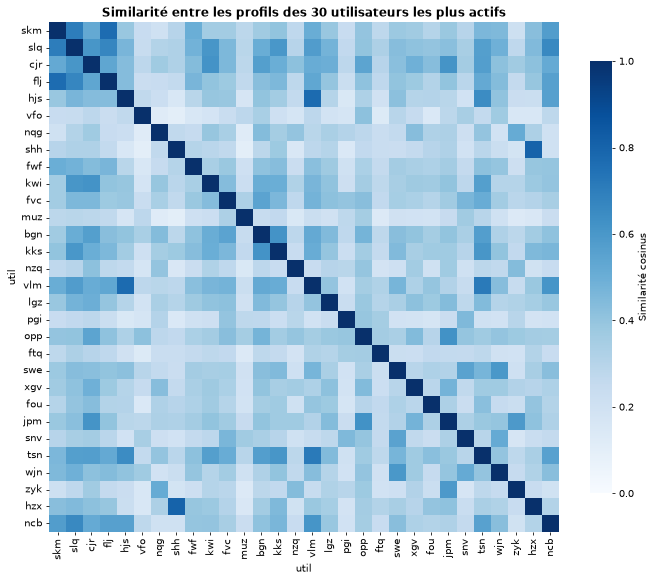

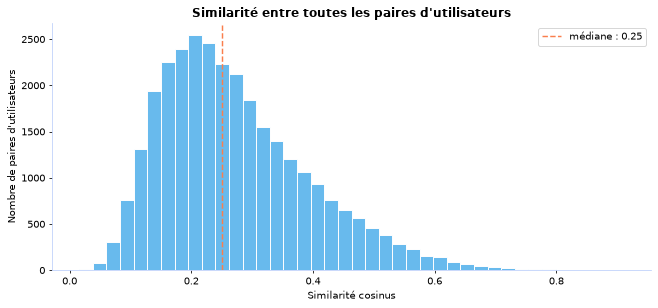

Paires d'utilisateurs les plus proches (risque de confusion) :
  ptb et txk : similarité 0.91
  ptb et sdx : similarité 0.91
  txk et sdx : similarité 0.89
  wuy et nkb : similarité 0.88
  wwk et wcf : similarité 0.88


In [17]:
# ===== VISUALISATION : similarité entre profils d'utilisateurs =====
tfidf_exploration = TfidfVectorizer(token_pattern=r"\S+", lowercase=False, sublinear_tf=True, min_df=2)
X_exploration = tfidf_exploration.fit_transform(table_train["doc_actions"])

utilisateurs = effectifs.index.astype(str)
profils_tfidf = np.vstack([np.asarray(X_exploration[(table_train["util"] == u).to_numpy()].mean(axis=0))
                           for u in utilisateurs])
profils_tfidf = normalize(profils_tfidf)
similarites = pd.DataFrame(profils_tfidf @ profils_tfidf.T, index=utilisateurs, columns=utilisateurs)

plt.figure(figsize=(10, 8.5))
sns.heatmap(similarites.iloc[:30, :30], cmap="Blues", vmin=0, vmax=1, square=True,
            cbar_kws={"label": "Similarité cosinus", "shrink": 0.8})
plt.title("Similarité entre les profils des 30 utilisateurs les plus actifs")
plt.tight_layout()
plt.show()

haut = np.triu_indices(len(utilisateurs), k=1)
valeurs = similarites.to_numpy()[haut]
plt.figure()
plt.hist(valeurs, bins=40, color=BLEU, edgecolor="white")
plt.axvline(np.median(valeurs), color=ORANGE, linestyle="--", label=f"médiane : {np.median(valeurs):.2f}")
plt.title("Similarité entre toutes les paires d'utilisateurs")
plt.xlabel("Similarité cosinus")
plt.ylabel("Nombre de paires d'utilisateurs")
plt.legend()
plt.tight_layout()
plt.show()

print("Paires d'utilisateurs les plus proches (risque de confusion) :")
for i in np.argsort(-valeurs)[:5]:
    print(f"  {utilisateurs[haut[0][i]]} et {utilisateurs[haut[1][i]]} : similarité {valeurs[i]:.2f}")

**Ce que l'on observe.** La similarité médiane entre deux utilisateurs n'est que de **0,25**, et très peu de
paires dépassent 0,6 : dans leur grande majorité, les utilisateurs ont des façons de travailler bien distinctes.
Quelques paires sont en revanche très proches : **ptb, txk et sdx** forment un trio (similarités de 0,89 à 0,91),
probablement des collègues qui font le même travail, de même que **wuy et nkb** ou **wwk et wcf** (0,88).
Ce sont ces utilisateurs que le modèle risque de confondre : on le vérifiera en section 3.5.

## 2.7 Synthèse : ce que l'exploration apporte à la modélisation

| Constat | Conséquence pour le modèle |
| --- | --- |
| Classes déséquilibrées (4 à 75 sessions, médiane 12) | découpage stratifié, suivi du F1 macro, test de `class_weight` |
| Un utilisateur = un seul navigateur, Opera = une seule personne | navigateur en one-hot |
| Les actions rares et surtout les composants (χ² jusqu'à 1 300) distinguent les utilisateurs | TF-IDF des jetons complets et des composants |
| Habitudes d'enchaînement différentes | TF-IDF des bigrammes de types d'action |
| Longueurs et durées très dispersées et asymétriques | fréquences (TF-IDF) plutôt que comptes, logarithme des durées |
| Similarité médiane faible (0,25) entre profils | les utilisateurs sont séparables : un modèle linéaire devrait bien fonctionner |

---
# Section 3 . Modèles de classification

## 3.1 Variables utilisées
Chaque session est transformée en un vecteur numérique par `construire_preparation` :

| Groupe | Construction | Ce qu'il décrit |
| --- | --- | --- |
| `actions` | TF-IDF des jetons complets (type + écran + configuration + chaîne) | ce que fait l'utilisateur et où |
| `enchainements` | TF-IDF des types d'action seuls et des paires d'actions consécutives (n-grammes 1 à 2) | dans quel ordre il le fait |
| `composants` | TF-IDF des écrans, configurations et chaînes | les parties du logiciel qu'il utilise |
| `navigateur` | one-hot | son navigateur |
| `statistiques` | log du nombre d'actions et de la durée, cadence, nb de types, part d'actions distinctes, entropie, nb d'écrans (centrées réduites) | son rythme de travail |

Le TF-IDF ne garde que les jetons présents dans au moins 2 sessions (`min_df=2`) : un jeton vu une seule fois ne
peut pas aider à reconnaître quelqu'un sur une nouvelle session.

La préparation fait partie d'un `Pipeline` : le vocabulaire du TF-IDF et les moyennes du `StandardScaler` sont
appris **uniquement** sur les données d'apprentissage, jamais sur la validation ou le test.

## 3.2 Découpage apprentissage / validation
On garde 75 % des sessions de `train.csv` pour **apprendre** et 25 % pour **valider**. Le découpage est
**stratifié** : chaque utilisateur est présent dans les deux parties dans la même proportion.

In [18]:
# ===== MODÈLE : découpage et dimension des variables =====
app, val = AN.decouper_apprentissage_validation(table_train, part_validation=0.25)

preparation = AN.construire_preparation().fit(app)
groupes = pd.Series(preparation.get_feature_names_out()).str.split("__").str[0].value_counts()
print(f"Nombre total de variables : {groupes.sum()}")
groupes.rename("nombre de variables")

Apprentissage : 2458 sessions | Validation : 820 sessions
Nombre total de variables : 5593


actions          4111
enchainements     939
composants        532
statistiques        7
navigateur          4
Name: nombre de variables, dtype: int64

**Ce que l'on observe.** **2 458 sessions** servent à apprendre et **820** à valider. Chaque session devient un
vecteur de **5 593 variables** : 4 111 jetons d'action complets, 939 types et paires d'actions, 532 composants,
7 statistiques et 4 navigateurs. Il y a donc plus de variables que de sessions : c'est le cadre classique où les
modèles **linéaires régularisés** fonctionnent bien.

## 3.3 Comparaison des modèles

| Modèle | Principe |
| --- | --- |
| Référence | répond toujours l'utilisateur le plus fréquent : le score minimum à battre |
| Régression logistique | modèle linéaire qui estime la probabilité de chaque utilisateur |
| SVM linéaire | cherche, pour chaque utilisateur, l'hyperplan qui le sépare des autres avec la plus grande marge |
| Perceptron multicouche (MLP) | réseau de neurones à une couche cachée : peut combiner les variables de façon non linéaire |
| Arbre de décision | suite de questions simples sur les variables ; facile à interpréter |
| Forêt aléatoire | moyenne de nombreux arbres construits sur des échantillons et des variables tirés au hasard |

Tous les modèles utilisent exactement la même préparation et le même découpage.

In [19]:
# ===== MODÈLE : entraînement et évaluation =====
modeles = AN.creer_modeles()
resultats, predictions, pipelines = AN.comparer_modeles(modeles, app, val)
resultats.round(3)

Référence (utilisateur le plus fréquent)   F1 validation = 0.023  (8.1 s)
Régression logistique                      F1 validation = 0.920  (25.3 s)
SVM linéaire                               F1 validation = 0.957  (6.3 s)
Perceptron multicouche (MLP)               F1 validation = 0.930  (28.2 s)
Arbre de décision                          F1 validation = 0.759  (13.7 s)
Forêt aléatoire                            F1 validation = 0.926  (12.1 s)


,Accuracy,F1 micro,F1 macro,F1 pondéré,F1 apprentissage,F1 validation,Temps (s)
SVM linéaire,0.957,0.957,0.951,0.954,1.000,0.957,6.321
Perceptron multicouche (MLP),0.930,0.930,0.922,0.927,1.000,0.930,28.215
Forêt aléatoire,0.926,0.926,0.899,0.915,1.000,0.926,12.129
Régression logistique,0.920,0.920,0.905,0.915,1.000,0.920,25.289
Arbre de décision,0.759,0.759,0.700,0.751,1.000,0.759,13.682
Référence (utilisateur le plus fréquent),0.023,0.023,0.000,0.001,0.023,0.023,8.103


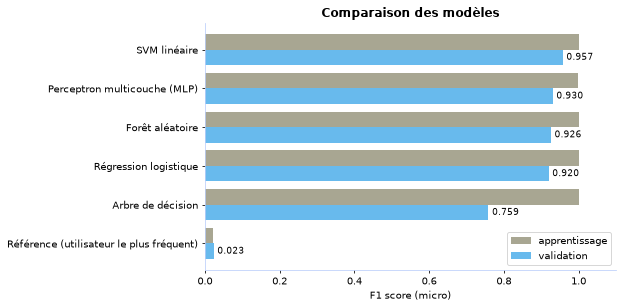

Meilleur modèle avant optimisation : SVM linéaire


In [20]:
# ===== MODÈLE : visualisation des résultats =====
AN.tracer_comparaison_modeles(resultats)
nom_meilleur = resultats.index[0]
print(f"Meilleur modèle avant optimisation : {nom_meilleur}")

**Ce que l'on observe.**

| Modèle | F1 micro (validation) | F1 macro | Temps |
| --- | :---: | :---: | :---: |
| **SVM linéaire** | **0,957** | **0,951** | 6 s |
| Perceptron multicouche | 0,930 | 0,922 | 28 s |
| Forêt aléatoire | 0,926 | 0,899 | 12 s |
| Régression logistique | 0,920 | 0,905 | 25 s |
| Arbre de décision | 0,759 | 0,700 | 14 s |
| Référence | 0,023 | 0,000 | 8 s |

* La **référence** (répondre toujours skm) ne trouve que 2,3 % des sessions : c'est la part de skm dans les données.
  Tous les modèles font plus de 30 fois mieux.
* Le **SVM linéaire** est à la fois le meilleur (95,7 % des sessions bien attribuées) et le plus rapide.
  Son F1 macro (0,951) est très proche du micro : il reconnaît aussi bien les petits utilisateurs que les gros.
* Tous les modèles obtiennent **1,000 sur l'apprentissage** : avec 5 593 variables, chaque session apprise est
  facile à mémoriser. C'est l'écart avec la validation qui mesure le sur-apprentissage : il est faible pour le SVM
  (0,04), énorme pour l'**arbre de décision** (0,24), qui apprend par cœur des règles trop précises.
* La **forêt aléatoire** corrige en grande partie ce défaut (0,926) en moyennant 300 arbres, mais son F1 macro
  (0,899) montre qu'elle reconnaît moins bien les utilisateurs rares.

Ce classement correspond à ce qu'on attendait : sur des données de grande dimension et creuses comme le TF-IDF,
les **modèles linéaires à marge** comme le SVM sont habituellement les plus efficaces.

## 3.4 Stabilité du score : validation croisée
Un seul découpage peut être favorable ou défavorable par hasard. On vérifie le score du meilleur modèle en
**validation croisée stratifiée à 5 plis** sur tout `train.csv`.

In [21]:
# ===== MODÈLE : validation croisée du meilleur modèle =====
moyenne, ecart_type = AN.validation_croisee(AN.creer_pipeline(modeles[nom_meilleur]), table_train, plis=5)
print(f"{nom_meilleur} : F1 = {moyenne:.3f} ± {ecart_type:.3f} (5 plis)")

SVM linéaire : F1 = 0.970 ± 0.003 (5 plis)


**Ce que l'on observe.** Le SVM linéaire obtient **F1 = 0,970 ± 0,003** sur les 5 plis. L'écart type est
minuscule : le score ne dépend pas du hasard du découpage. Il est même un peu plus élevé que sur la partie
validation (0,957) parce que chaque pli apprend sur 80 % de toutes les données au lieu de 75 % : plus d'exemples
par utilisateur, meilleure reconnaissance. C'est un bon signe pour le modèle final, entraîné sur 100 % du train.

## 3.5 Analyse des erreurs

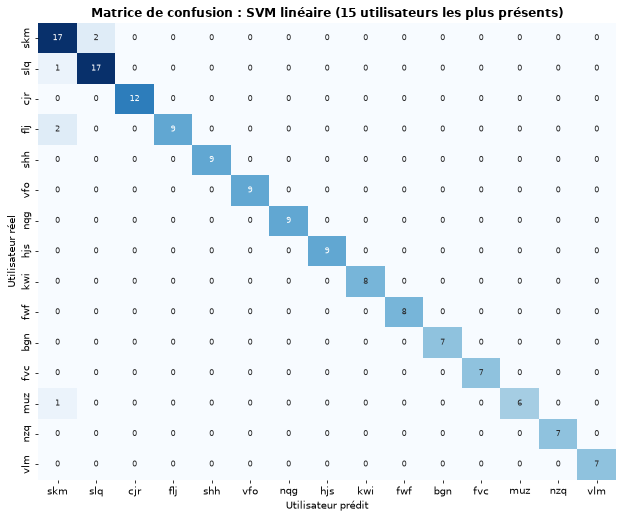

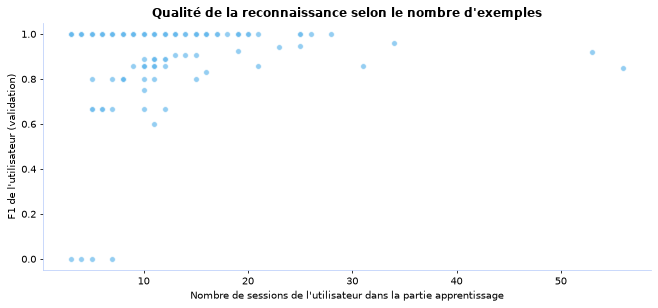

Utilisateurs les moins bien reconnus :


,n_sessions,f1
eqw,5,0.000000
hll,7,0.000000
jew,3,0.000000
ufc,4,0.000000
guh,11,0.600000
iyf,6,0.666667
nkb,5,0.666667
bos,7,0.666667
xkr,10,0.666667
uof,6,0.666667


In [22]:
# ===== MODÈLE : matrice de confusion et F1 par utilisateur =====
utilisateurs_frequents = val["util"].value_counts().head(15).index
AN.tracer_matrice_confusion(val["util"], predictions[nom_meilleur], utilisateurs_frequents,
                            titre=f"Matrice de confusion : {nom_meilleur} (15 utilisateurs les plus présents)")

par_utilisateur = AN.tracer_f1_par_utilisateur(val["util"], predictions[nom_meilleur], app["util"])
print("Utilisateurs les moins bien reconnus :")
par_utilisateur.head(10)

**Ce que l'on observe.**
* Sur les 15 utilisateurs les plus présents, la matrice de confusion est presque parfaitement **diagonale** :
  seulement 6 erreurs sur 151 sessions. Elles vont presque toutes **vers skm**, l'utilisateur le plus fréquent
  (2 sessions de slq et 2 de flj attribuées à skm), et 2 sessions de skm sont attribuées à slq.
  Les deux plus gros utilisateurs « attirent » donc un peu les sessions ambiguës.
* Le nuage de points confirme l'intuition de la section 2.1 : **tous les utilisateurs qui ont plus de 20 sessions
  d'apprentissage sont reconnus avec un F1 supérieur à 0,85**, alors que les erreurs se concentrent chez ceux qui en
  ont moins de 15.
* **4 utilisateurs ont un F1 de 0** (eqw, hll, jew, ufc) : ils n'ont que 3 à 7 sessions d'apprentissage, et leurs
  1 ou 2 sessions de validation ont été attribuées à quelqu'un d'autre.
* On retrouve **nkb** parmi les moins bien reconnus (F1 = 0,67) : c'est l'un des utilisateurs dont le profil est le plus
  proche d'un autre (0,88 avec wuy, section 2.6). L'analyse de similarité annonçait bien ces confusions.

## 3.6 Interprétation : les deux modèles à base d'arbres
L'arbre de décision montre les premières questions posées par le modèle ; la forêt aléatoire donne l'importance
de chaque variable (diminution moyenne de l'impureté de Gini).

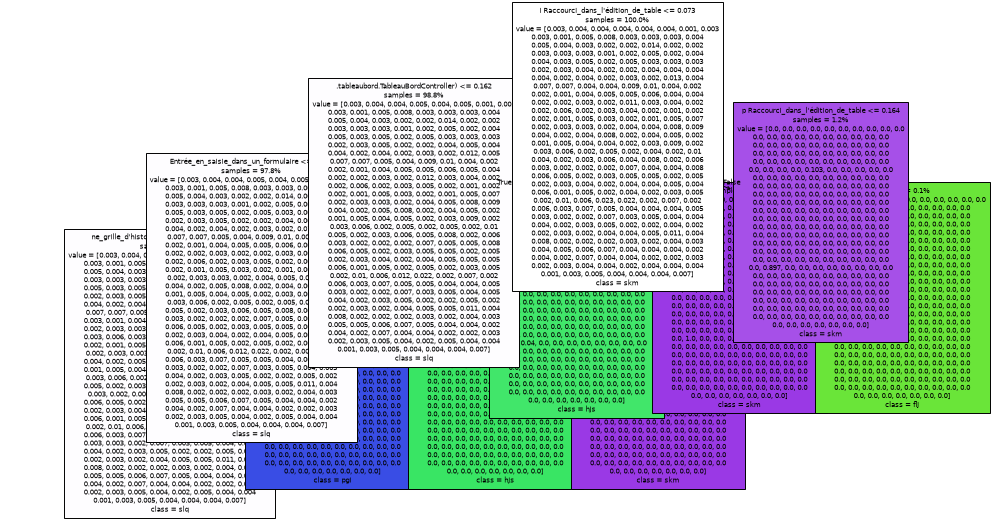

In [23]:
# ===== MODÈLE : arbre de décision =====
AN.tracer_arbre(pipelines["Arbre de décision"], profondeur=3)

**Ce que l'on observe.** La première question de l'arbre porte sur le poids TF-IDF de l'action
**« Raccourci dans l'édition de table »** ; viennent ensuite l'ouverture d'un **tableau de bord**,
l'**entrée en saisie dans un formulaire** et le **clic sur une grille d'historique de recherche**. Ce sont exactement
des actions repérées par le test du χ² en section 2.3 : rares, mais très typiques de certains utilisateurs.
Chaque question ne sépare toutefois qu'un petit groupe de sessions (moins de 3 %), ce qui explique qu'il faille un
arbre très profond, et donc fragile, pour distinguer 247 personnes.

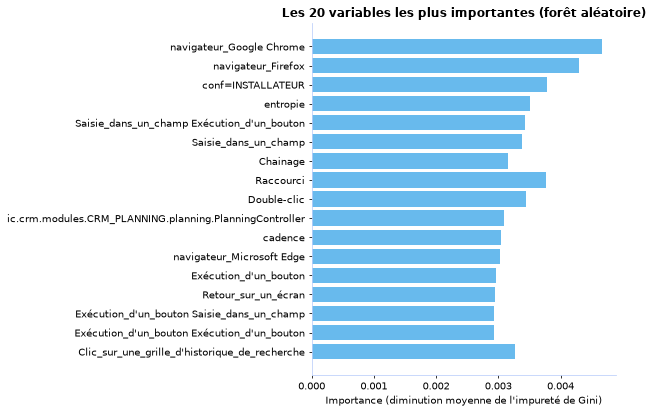

enchainements    0.506
actions          0.340
composants       0.123
statistiques     0.018
navigateur       0.013
Name: importance totale, dtype: float64

In [24]:
# ===== MODÈLE : importance des variables (forêt aléatoire) =====
importances = AN.tracer_importance_variables(pipelines["Forêt aléatoire"], n=20,
                                             titre="Les 20 variables les plus importantes (forêt aléatoire)")
AN.importance_par_groupe(importances)

**Ce que l'on observe.**
* **Variable par variable**, les plus importantes pour la forêt sont **le navigateur** (Chrome et Firefox en tête),
  puis la configuration `INSTALLATEUR`, l'**entropie** de la session, la paire « Saisie dans un champ → Exécution
  d'un bouton », les actions « Saisie dans un champ », « Chainage », « Raccourci », « Double-clic », l'écran de
  planning du CRM et la **cadence**.
* **Par famille**, les enchaînements (0,51) et les jetons d'action (0,34) totalisent la plus grande part de
  l'importance, devant les composants (0,12), les statistiques (0,02) et le navigateur (0,01). Ce n'est pas une
  contradiction : ces familles contiennent des centaines de variables qui ajoutent chacune un peu d'information,
  alors que le navigateur n'en contient que 4, individuellement très utiles.

La reconnaissance repose donc sur une combinaison : le navigateur et le rythme réduisent le nombre de candidats,
et les actions, leurs enchaînements et les écrans utilisés départagent les candidats restants.

---
# Section 4 . Optimisation du modèle et soumission

On améliore les modèles **étape par étape**, avec une **recherche sur grille** (`GridSearchCV`) en validation
croisée à 3 plis, **uniquement sur la partie apprentissage** La partie validation ne sert à aucun réglage : le gain
mesuré dessus est donc une estimation honnête.

## 4.1 Paramètre de régularisation
Pour la régression logistique et le SVM, `C` règle la régularisation : un `C` petit donne un modèle très simple
(risque de sous-apprentissage), un `C` grand un modèle qui colle aux données d'apprentissage (risque de
sur-apprentissage).

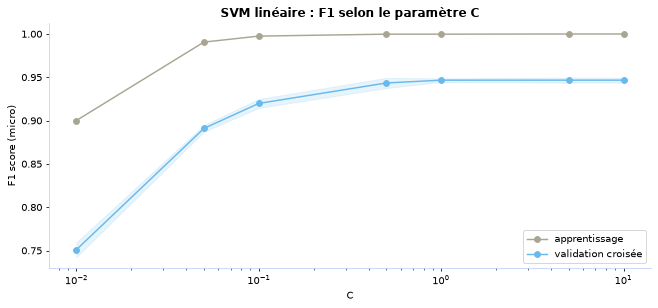

Meilleure valeur : 1 (F1 = 0.947)


In [25]:
# ===== OPTIMISATION : courbe de validation du paramètre C =====
C_svm = AN.tracer_courbe_validation(AN.creer_pipeline(modeles["SVM linéaire"]), app, app["util"],
                                    "modele__C", [0.01, 0.05, 0.1, 0.5, 1, 5, 10],
                                    titre="SVM linéaire : F1 selon le paramètre C")

**Ce que l'on observe.** Avec un `C` très petit (0,01), le modèle est trop contraint et n'atteint que 0,75 en
validation croisée (sous-apprentissage). Le score monte ensuite rapidement et se stabilise à **0,947 à partir de
C = 1**. La courbe d'apprentissage (grise) atteint 1 dès C = 0,1, mais la courbe de validation ne redescend pas
pour les grands `C` : le SVM ne se dégrade pas en collant aux données. **C = 1**, la valeur de départ, est donc
déjà le bon choix.

## 4.2 Recherche sur grille pour chaque modèle
Paramètres testés :
* `C` et la pondération des classes (`class_weight="balanced"` : une erreur sur un utilisateur rare coûte plus
  cher) pour les modèles linéaires ;
* taille de la couche cachée et régularisation `alpha` pour le MLP ;
* profondeur maximale, taille minimale des feuilles et pondération des classes pour l'arbre ;
* nombre d'arbres, nombre de variables tirées à chaque division et pondération des classes pour la forêt.

In [26]:
# ===== OPTIMISATION : recherche sur grille pour chaque modèle =====
optimisation, modeles_optimises = AN.optimiser_tous_les_modeles(modeles, app, val, resultats)
optimisation

Régression logistique            0.920 -> 0.917  (331 s)
SVM linéaire                     0.957 -> 0.957  (120 s)
Perceptron multicouche (MLP)     0.930 -> 0.938  (806 s)
Arbre de décision                0.759 -> 0.780  (324 s)
Forêt aléatoire                  0.926 -> 0.934  (466 s)


,F1 validation croisée,F1 validation avant,F1 validation après,Gain,Meilleurs paramètres
SVM linéaire,0.946704,0.957317,0.957317,0.0,"{'C': 1, 'class_weight': None}"
Perceptron multicouche (MLP),0.929618,0.930488,0.937805,0.007317,"{'alpha': 0.01, 'hidden_layer_sizes': (512,)}"
Forêt aléatoire,0.918228,0.92561,0.934146,0.008537,"{'class_weight': None, 'max_features': 'sqrt',..."
Régression logistique,0.903578,0.919512,0.917073,-0.002439,"{'C': 100, 'class_weight': None}"
Arbre de décision,0.721318,0.758537,0.780488,0.021951,"{'class_weight': 'balanced', 'max_depth': None..."


**Ce que l'on observe.**

| Modèle | F1 validation croisée | F1 validation avant → après | Meilleurs paramètres |
| --- | :---: | :---: | --- |
| **SVM linéaire** | **0,947** | 0,957 → **0,957** | `C = 1`, sans pondération |
| Perceptron multicouche | 0,930 | 0,930 → 0,938 | 512 neurones, `alpha = 0,01` |
| Forêt aléatoire | 0,918 | 0,926 → 0,934 | `max_features = "sqrt"`, sans pondération |
| Régression logistique | 0,904 | 0,920 → 0,917 | `C = 100`, sans pondération |
| Arbre de décision | 0,721 | 0,759 → 0,780 | `class_weight = "balanced"`, profondeur libre |

* Les gains sont **faibles** (au plus +0,022 pour l'arbre) : nos paramètres de départ étaient déjà raisonnables.
  Le MLP et la forêt progressent un peu grâce à plus de neurones / de régularisation et à plus d'arbres.
* La **pondération des classes** n'est retenue que pour l'arbre : pour les autres modèles, elle n'améliore pas le
  score, car le SVM reconnaît déjà bien les utilisateurs rares (F1 macro 0,951).
* La régression logistique baisse très légèrement sur la validation (−0,002) alors que la validation croisée la
  préférait avec `C = 100` : c'est une variation dans le bruit, sur 2 sessions.
* **Le SVM linéaire reste le meilleur modèle**, aussi bien en validation croisée qu'en validation, avec les mêmes
  paramètres. C'est lui qui est retenu pour la suite.

## 4.3 Réglage de la préparation des variables
Les modèles sont classés selon leur score en **validation croisée** (calculé sur la seule partie apprentissage) :
c'est le SVM linéaire qui arrive en tête. Sur ce modèle, on règle ensuite la préparation : fréquence minimale
d'un jeton pour entrer dans le vocabulaire (`min_df` = 1, 2 ou 3) et longueur maximale des enchaînements
d'actions (`ngram_range` jusqu'à 1, 2 ou 3 actions consécutives).

In [ ]:
# ===== OPTIMISATION : réglage de la préparation des variables =====
nom_final = optimisation.index[0]
recherche_preparation = AN.optimiser_modele(modeles_optimises[nom_final], AN.GRILLE_PREPARATION, app)
print(f"Modèle : {nom_final}")
AN.resume_recherche(recherche_preparation)

**Ce que l'on observe.** La meilleure préparation garde **tous les jetons** (`min_df = 1`) et ajoute les
**triplets d'actions consécutives** (`ngram_range = (1, 3)`) : F1 = **0,948 ± 0,006** en validation croisée, contre
0,947 ± 0,002 pour la préparation de départ (`min_df = 2`, paires d'actions). L'écart (+0,002) est plus petit que
l'écart type entre les plis : les cinq meilleures combinaisons sont **à égalité**, à quelques millièmes près.
La représentation est donc robuste : le résultat ne dépend pas d'un réglage fin du vocabulaire.

## 4.4 Performances initiales et optimisées
Les deux versions sont entraînées sur la même partie apprentissage et évaluées sur la même partie validation.
Le tableau ci-dessous donne le gain final de toute l'optimisation (paramètres du modèle et préparation).

In [ ]:
# ===== OPTIMISATION : bilan sur la partie validation =====
pipeline_final = recherche_preparation.best_estimator_
y_final = pipeline_final.predict(val)

bilan = pd.DataFrame({
    f"{nom_meilleur} (initial)": AN.calculer_scores(val["util"], predictions[nom_meilleur]),
    f"{nom_final} (optimisé)": AN.calculer_scores(val["util"], y_final),
}).T
bilan.round(3)

**Ce que l'on observe.** Sur la partie validation, le modèle optimisé obtient **0,956** (F1 macro 0,950) contre
0,957 pour le modèle initial : une différence d'**une seule session sur 820**. L'optimisation ne change donc rien de
significatif, ce qui confirme les deux constats précédents : `C = 1` était déjà le bon choix, et toutes les
préparations testées se valent. Nous gardons la version optimisée, choisie de façon honnête sur la validation
croisée (la partie validation n'a servi à aucun réglage).

## 4.5 Entraînement final et prédiction sur `test.csv`
C'est seulement maintenant que l'on utilise `test.csv`. Le modèle retenu, avec ses paramètres optimisés, est
réentraîné sur **toutes** les sessions de `train.csv` (plus de données = meilleur modèle, comme l'a montré la
validation croisée), puis appliqué aux 324 sessions du test. Le fichier `submission.csv` est ensuite déposé sur
Kaggle et sur Moodle.

In [ ]:
# ===== SOUMISSION : entraînement final et prédiction sur test.csv =====
modele_final = AN.entrainer_modele_final(pipeline_final, table_train)
predictions_test = modele_final.predict(table_test)
soumission = AN.ecrire_soumission(predictions_test, "submission.csv")
soumission.head()

In [ ]:
# ===== SOUMISSION : vérifications =====
# 1) Le navigateur de chaque session de test doit être celui de l'utilisateur prédit
navigateur_util = table_train.groupby("util")["navigateur"].agg(lambda s: s.mode()[0])
coherence = (navigateur_util.loc[predictions_test].to_numpy() == table_test["navigateur"].to_numpy()).mean()
print(f"Sessions de test dont le navigateur correspond à l'utilisateur prédit : {coherence:.1%}")

# 2) Répartition des prédictions
print(f"Nombre d'utilisateurs différents prédits : {pd.Series(predictions_test).nunique()}")
pd.Series(predictions_test).value_counts().head(10)

**Ce que l'on observe.**
* Les **324 sessions** du test ont reçu une prédiction, au format attendu (`RowId`, `prediction`).
* Pour **100 %** des sessions, le navigateur de la session est bien celui de l'utilisateur prédit : le modèle
  n'a jamais proposé une personne incompatible.
* Les prédictions sont **variées** : **223 utilisateurs différents** pour 324 sessions, et les plus prédits sont
  slq (8 sessions) et skm (6), les deux utilisateurs les plus présents dans le train. Le modèle ne se contente donc
  pas de répondre toujours les mêmes personnes.

---
# Section 5 . Conclusion

### Ce que nous avons construit
Nous avons mis en place une chaîne de traitement complète, de la trace brute jusqu'à la soumission Kaggle :

1. **Préparation** : une lecture adaptée à des lignes de 14 à 14 470 champs, le découpage de chaque jeton en
   action, écran, configuration et chaîne, un contrôle de qualité (1 session vide retirée, 9 jetons atypiques sur
   2,27 millions) et le passage au logarithme des durées plutôt que la suppression des longues sessions.
2. **Exploration** : elle nous a montré où se cache l'identité d'un utilisateur. Chacun garde **toujours le même
   navigateur** ; les actions les plus fréquentes sont communes à tous, mais les **actions rares** (formulaires,
   flags, tableaux de bord, raccourcis) et surtout les **chaînes et écrans utilisés** (χ² jusqu'à 1 300) sont très
   personnels ; les profils sont globalement peu similaires (médiane 0,25).
3. **Variables** : 5 593 variables par session, construites directement à partir de ces constats : TF-IDF des
   jetons, des enchaînements et des composants, navigateur et statistiques de rythme.
4. **Modèles** : cinq méthodes vues en cours comparées sur le même découpage stratifié, puis optimisées par
   recherche sur grille en validation croisée, sans jamais toucher à la partie validation ni au test.

### Ce que nous retenons
* Le **SVM linéaire** est le meilleur modèle : **F1 = 0,957** en validation (0,951 en macro) et
  **0,970 ± 0,003** en validation croisée, pour 6 secondes d'entraînement. Sur des données de grande dimension et
  creuses, une séparation linéaire à marge maximale suffit : le MLP (0,938 après optimisation) et la forêt (0,934)
  ne font pas mieux, et l'arbre de décision seul sur-apprend (0,780).
* L'optimisation a peu changé les résultats : le modèle final (SVM, `C = 1`, tous les jetons, enchaînements de 1 à
  3 actions) obtient 0,948 en validation croisée et 0,956 en validation, à une session près du modèle de départ.
  Nos choix de variables comptaient beaucoup plus que le réglage fin des paramètres.
  **La qualité de la représentation fait la qualité du modèle.**
* Sur le test, les 324 prédictions sont cohérentes (navigateur compatible dans 100 % des cas) et variées
  (223 utilisateurs différents).
* Les erreurs restantes sont **compréhensibles** : elles touchent les utilisateurs qui ont très peu de sessions
  (4 utilisateurs avec 3 à 7 sessions ne sont jamais reconnus) et ceux qui travaillent comme un collègue
  (nkb, proche de wuy), et elles vont surtout vers l'utilisateur le plus fréquent.

### Limites et perspectives
* Avec 4 sessions pour certains utilisateurs, on ne peut pas faire de miracle : **plus de traces** par personne
  serait l'amélioration la plus efficace.
* La dimension temporelle reste peu exploitée (la durée est connue à 5 secondes près) : le rythme au début de
  la session, ou l'ordre des écrans visités, pourraient aider à séparer les collègues au profil proche.
* Pour la **détection d'intrusion** évoquée par Infologic, il faudrait savoir dire « je ne reconnais personne ».
  La distance d'une session à la frontière du SVM pourrait servir de score de confiance : une session loin de tous
  les profils connus serait signalée comme suspecte.

En résumé, **95 à 97 % des sessions sont attribuées au bon utilisateur à partir de la seule trace de ses actions** :
la façon dont chacun utilise Copilote est une véritable signature.